we are going to build and simulate multi-qubit quantum circuits using Qiskit. The goal is to understand how multiple qubits can interact, how a controlled gate works, and how different gate combinations produce deterministic or correlated measurement outcomes.

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

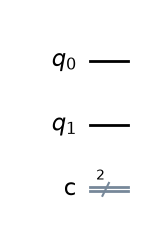

In [3]:
circuit = QuantumCircuit(2, 2)

circuit.draw("mpl")

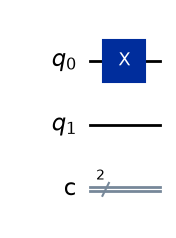

In [4]:
circuit.x(0)

circuit.draw("mpl")

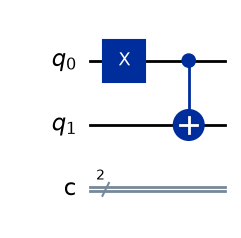

In [5]:
circuit.cx(0, 1)

circuit.draw("mpl")

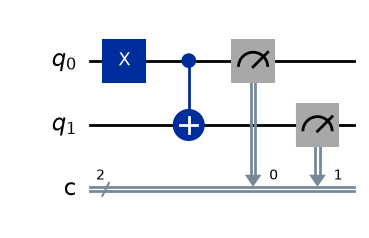

In [6]:
circuit.measure([0, 1], [0, 1])

circuit.draw("mpl")

In [7]:
simulator = AerSimulator()

In [8]:
result = simulator.run(
    circuit,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'11': 1000}


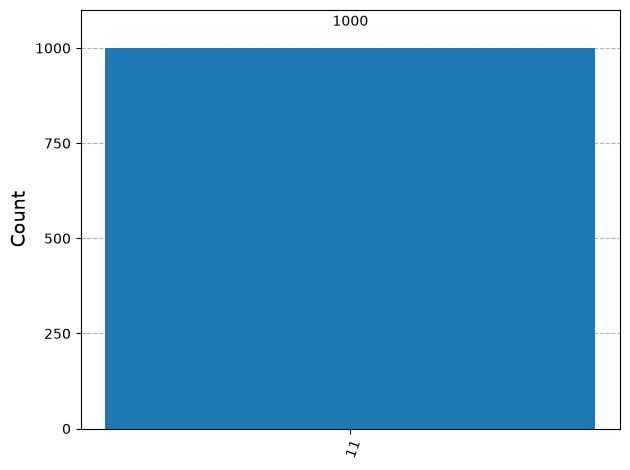

In [9]:
plot_histogram(counts)

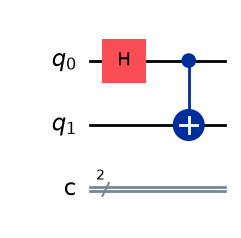

In [10]:
superposition_circuit = QuantumCircuit(2, 2)

superposition_circuit.h(0)
superposition_circuit.cx(0, 1)

superposition_circuit.draw("mpl")

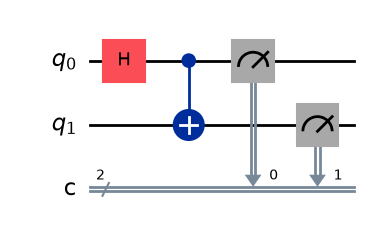

In [11]:
superposition_circuit.measure([0, 1], [0, 1])

superposition_circuit.draw("mpl")

In [12]:
bell_result = simulator.run(
    superposition_circuit,
    shots=1000
).result()

bell_counts = bell_result.get_counts()

print(bell_counts)

{'00': 505, '11': 495}


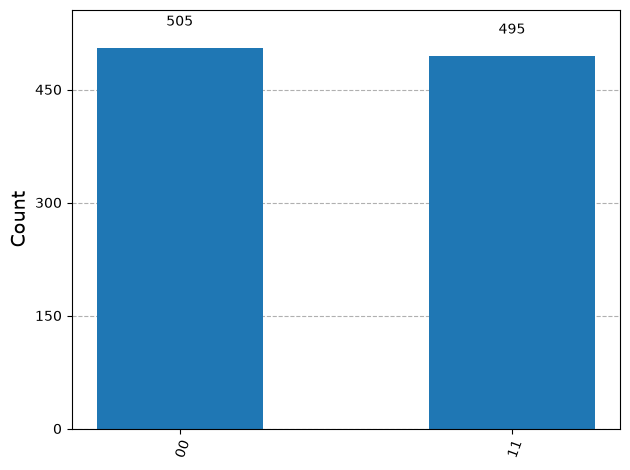

In [13]:
plot_histogram(bell_counts)

In [14]:
total_shots = sum(bell_counts.values())

probability_00 = bell_counts.get("00", 0) / total_shots
probability_11 = bell_counts.get("11", 0) / total_shots

print(f"Probability of |00>: {probability_00:.2%}")
print(f"Probability of |11>: {probability_11:.2%}")

Probability of |00>: 50.50%
Probability of |11>: 49.50%


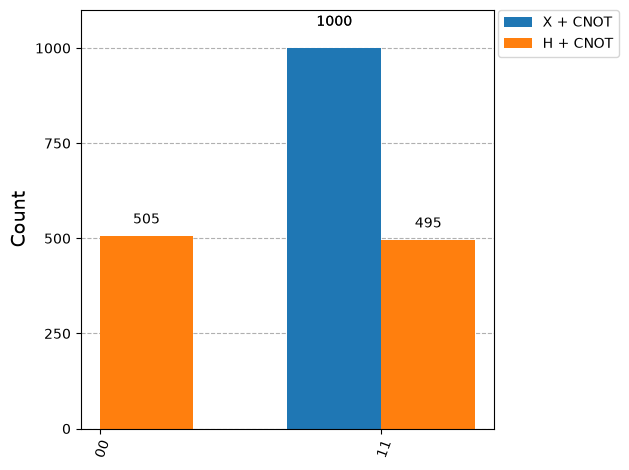

In [15]:
plot_histogram(
    [counts, bell_counts],
    legend=["X + CNOT", "H + CNOT"]
)